In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from tqdm import tqdm
from sklearn.model_selection import train_test_split

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

DATASET_PATH ="/content/drive/MyDrive/kvasir_dataset.zip.zip"

print("Dataset path:", DATASET_PATH)
print("Path exists:", os.path.exists(DATASET_PATH))

Dataset path: /content/drive/MyDrive/kvasir_dataset.zip.zip
Path exists: True


In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    print("ZIP file contents:\n")

    for item in zip_ref.namelist():
        print(item)

ZIP file contents:

kvasir-dataset/dyed-lifted-polyps/0053d7cd-549c-48cd-b370-b4ad64a8098a.jpg
kvasir-dataset/dyed-lifted-polyps/007d5aa7-7289-4bad-aa4a-5c3a259e9b19.jpg
kvasir-dataset/dyed-lifted-polyps/00cf9508-6ad1-4db9-840a-519c1d515c30.jpg
kvasir-dataset/dyed-lifted-polyps/01507fbd-4d38-4525-9768-7754710f507c.jpg
kvasir-dataset/dyed-lifted-polyps/018ed8ed-e489-4bbb-8a99-3346db9ec160.jpg
kvasir-dataset/dyed-lifted-polyps/0195c5a6-5ddf-471c-9868-2ea66b81f440.jpg
kvasir-dataset/dyed-lifted-polyps/01d38b8f-74b2-4147-9519-448d05bf8745.jpg
kvasir-dataset/dyed-lifted-polyps/02c10865-9d23-4f6b-aa5d-f73b63b6d67f.jpg
kvasir-dataset/dyed-lifted-polyps/031a6e89-d3b7-48c8-8e2f-db991030f959.jpg
kvasir-dataset/dyed-lifted-polyps/03a49a2e-c8d4-4dcd-b5e7-3d1722ed5db3.jpg
kvasir-dataset/dyed-lifted-polyps/041daea7-c9cd-43f9-ae77-b8ecb694a6a2.jpg
kvasir-dataset/dyed-lifted-polyps/04293e0c-1593-45d7-887f-3b6e413d97d4.jpg
kvasir-dataset/dyed-lifted-polyps/04391f36-f787-4acf-9312-ccc0e6e52f39.jpg
kvasi

In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    all_files = zip_ref.namelist()

    class_names = [
        "dyed-lifted-polyps",
        "dyed-resection-margins",
        "esophagitis",
        "normal-cecum",
        "normal-pylorus",
        "normal-z-line",
        "polyps",
        "ulcerative-colitis"
    ]

    for class_name in class_names:

        found = any(
            name.startswith(class_name + "/")
            or ("/" + class_name + "/") in name
            for name in all_files
        )

        print(class_name, ":", "Found" if found else "Not Found")

dyed-lifted-polyps : Found
dyed-resection-margins : Found
esophagitis : Found
normal-cecum : Found
normal-pylorus : Found
normal-z-line : Found
polyps : Found
ulcerative-colitis : Found


In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    image_files = [
        name for name in zip_ref.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Total images in ZIP:", len(image_files))

Total images in ZIP: 4000


In [ ]:
import zipfile
import os
from collections import Counter

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    files = [
        name for name in zip_ref.namelist()
        if not name.endswith("/")
    ]

    print("Total files:", len(files))

    extensions = Counter(
        os.path.splitext(name)[1].lower()
        for name in files
    )

    print("\nFile extensions:")
    print(extensions)

Total files: 4000

File extensions:
Counter({'.jpg': 4000})


In [ ]:
import zipfile
import os
from collections import Counter

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    class_counts = Counter()

    for name in zip_ref.namelist():

        if name.endswith("/"):
            continue

        parts = name.strip("/").split("/")

        for class_name in [
            "dyed-lifted-polyps",
            "dyed-resection-margins",
            "esophagitis",
            "normal-cecum",
            "normal-pylorus",
            "normal-z-line",
            "polyps",
            "ulcerative-colitis"
        ]:

            if class_name in parts:
                class_counts[class_name] += 1
                break

    for class_name, count in sorted(class_counts.items()):
        print(class_name, ":", count)

    print("\nTotal:", sum(class_counts.values()))

dyed-lifted-polyps : 500
dyed-resection-margins : 500
esophagitis : 500
normal-cecum : 500
normal-pylorus : 500
normal-z-line : 500
polyps : 500
ulcerative-colitis : 500

Total: 4000


In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    image_files = [
        name for name in zip_ref.namelist()
        if name.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        )
    ]

    unique_images = set(image_files)

    print("Total image entries:", len(image_files))
    print("Unique image paths:", len(unique_images))

Total image entries: 4000
Unique image paths: 4000


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

if os.path.exists(ZIP_PATH):
    print("ZIP file found!")
    print("File size:", round(os.path.getsize(ZIP_PATH) / (1024**3), 2), "GB")
else:
    print("ZIP file not found at this path.")

ZIP file found!
File size: 1.15 GB


In [ ]:
import zipfile

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    files = zip_ref.namelist()

print("Total files inside ZIP:", len(files))
print("First 10 entries:")

for file in files[:10]:
    print(file)

Total files inside ZIP: 4000
First 10 entries:
kvasir-dataset/dyed-lifted-polyps/0053d7cd-549c-48cd-b370-b4ad64a8098a.jpg
kvasir-dataset/dyed-lifted-polyps/007d5aa7-7289-4bad-aa4a-5c3a259e9b19.jpg
kvasir-dataset/dyed-lifted-polyps/00cf9508-6ad1-4db9-840a-519c1d515c30.jpg
kvasir-dataset/dyed-lifted-polyps/01507fbd-4d38-4525-9768-7754710f507c.jpg
kvasir-dataset/dyed-lifted-polyps/018ed8ed-e489-4bbb-8a99-3346db9ec160.jpg
kvasir-dataset/dyed-lifted-polyps/0195c5a6-5ddf-471c-9868-2ea66b81f440.jpg
kvasir-dataset/dyed-lifted-polyps/01d38b8f-74b2-4147-9519-448d05bf8745.jpg
kvasir-dataset/dyed-lifted-polyps/02c10865-9d23-4f6b-aa5d-f73b63b6d67f.jpg
kvasir-dataset/dyed-lifted-polyps/031a6e89-d3b7-48c8-8e2f-db991030f959.jpg
kvasir-dataset/dyed-lifted-polyps/03a49a2e-c8d4-4dcd-b5e7-3d1722ed5db3.jpg


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/kvasir_dataset.zip.zip"
EXTRACT_PATH = "/content/kvasir_extracted"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    total = len(zip_ref.namelist())

    for i, file in enumerate(zip_ref.namelist()):
        zip_ref.extract(file, EXTRACT_PATH)

        if (i + 1) % 500 == 0:
            print(f"Extracted {i + 1}/{total} files")

print("Dataset extraction completed!")

Extracted 500/4000 files
Extracted 1000/4000 files
Extracted 1500/4000 files
Extracted 2000/4000 files
Extracted 2500/4000 files
Extracted 3000/4000 files
Extracted 3500/4000 files
Extracted 4000/4000 files
Dataset extraction completed!


In [ ]:
import os

DATASET_PATH = "/content/kvasir_extracted/kvasir-dataset"

class_names = sorted(os.listdir(DATASET_PATH))

print("Total classes:", len(class_names))
print("-" * 40)

total_images = 0

for class_name in class_names:
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        total_images += count
        print(f"{class_name}: {count} images")

print("-" * 40)
print("Total images:", total_images)

Total classes: 8
----------------------------------------
dyed-lifted-polyps: 500 images
dyed-resection-margins: 500 images
esophagitis: 500 images
normal-cecum: 500 images
normal-pylorus: 500 images
normal-z-line: 500 images
polyps: 500 images
ulcerative-colitis: 500 images
----------------------------------------
Total images: 4000


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
import os
import random

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
Device: cuda
CUDA available: True


In [ ]:
IMG_SIZE = 64
BATCH_SIZE = 64
LATENT_DIM = 100
NUM_CLASSES = 8
EPOCHS = 50

LR = 0.0002
BETA1 = 0.5

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Latent Dimension:", LATENT_DIM)
print("Number of Classes:", NUM_CLASSES)
print("Epochs:", EPOCHS)
print("Learning Rate:", LR)

Image Size: 64
Batch Size: 64
Latent Dimension: 100
Number of Classes: 8
Epochs: 50
Learning Rate: 0.0002


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATASET_PATH = "/content/kvasir_extracted/kvasir-dataset"

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

print("Dataset size:", len(dataset))
print("Classes:", dataset.classes)
print("Number of batches:", len(train_loader))

Dataset size: 4000
Classes: ['dyed-lifted-polyps', 'dyed-resection-margins', 'esophagitis', 'normal-cecum', 'normal-pylorus', 'normal-z-line', 'polyps', 'ulcerative-colitis']
Number of batches: 62


In [ ]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel minimum:", images.min().item())
print("Pixel maximum:", images.max().item())
print("Unique labels:", torch.unique(labels))

Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])
Pixel minimum: -1.0
Pixel maximum: 1.0
Unique labels: tensor([0, 1, 2, 3, 4, 5, 6, 7], device='cuda:0')


In [ ]:
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()

        self.label_embedding = nn.Embedding(NUM_CLASSES, 50)

        self.fc = nn.Sequential(
            nn.Linear(LATENT_DIM + 50, 4096),
            nn.BatchNorm1d(4096),
            nn.ReLU(True)
        )

        self.model = nn.Sequential(
            nn.Unflatten(1, (256, 4, 4)),

            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),

            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_embedding = self.label_embedding(labels)

        combined = torch.cat(
            (noise, label_embedding), dim=1
        )

        output = self.fc(combined)
        output = self.model(output)

        return output


generator = Generator().to(device)

print(generator)

Generator(
  (label_embedding): Embedding(8, 50)
  (fc): Sequential(
    (0): Linear(in_features=150, out_features=4096, bias=True)
    (1): BatchNorm1d(4096, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (model): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(256, 4, 4))
    (1): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.label_embedding = nn.Embedding(
            NUM_CLASSES, IMG_SIZE * IMG_SIZE
        )

        self.model = nn.Sequential(
            nn.Conv2d(4, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(256 * 8 * 8, 1),
            nn.Sigmoid()
        )

    def forward(self, images, labels):
        label_embedding = self.label_embedding(labels)

        label_embedding = label_embedding.view(
            labels.size(0), 1, IMG_SIZE, IMG_SIZE
        )

        combined = torch.cat(
            (images, label_embedding), dim=1
        )

        return self.model(combined)


discriminator = Discriminator().to(device)

print(discriminator)

Discriminator(
  (label_embedding): Embedding(8, 4096)
  (model): Sequential(
    (0): Conv2d(4, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=16384, out_features=1, bias=True)
    (10): Sigmoid()
  )
)


In [ ]:
criterion = nn.BCELoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LR,
    betas=(BETA1, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LR,
    betas=(BETA1, 0.999)
)

print("Loss Function:", criterion)
print("Generator Optimizer:", optimizer_G)
print("Discriminator Optimizer:", optimizer_D)
print("GAN setup completed successfully!")


Loss Function: BCELoss()
Generator Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)
Discriminator Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.5, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0002
    maximize: False
    weight_decay: 0
)
GAN setup completed successfully!


In [ ]:
generator.eval()
discriminator.eval()

with torch.no_grad():
    test_noise = torch.randn(8, LATENT_DIM, device=device)
    test_labels = torch.arange(NUM_CLASSES, device=device)

    fake_images = generator(test_noise, test_labels)

    predictions = discriminator(fake_images, test_labels)

print("Generated images shape:", fake_images.shape)
print("Discriminator output shape:", predictions.shape)
print("Generated image minimum:", fake_images.min().item())
print("Generated image maximum:", fake_images.max().item())
print("Model testing completed!")

Generated images shape: torch.Size([8, 3, 64, 64])
Discriminator output shape: torch.Size([8, 1])
Generated image minimum: -0.1485850214958191
Generated image maximum: 0.06767616420984268
Model testing completed!


In [ ]:
def train_gan(num_epochs):

    generator.train()
    discriminator.train()

    for epoch in range(num_epochs):

        g_loss_total = 0.0
        d_loss_total = 0.0

        for real_images, real_labels in train_loader:

            real_images = real_images.to(device)
            real_labels = real_labels.to(device)

            batch_size = real_images.size(0)

            real_targets = torch.ones(batch_size, 1, device=device)
            fake_targets = torch.zeros(batch_size, 1, device=device)

            # Train Discriminator
            optimizer_D.zero_grad()

            real_output = discriminator(real_images, real_labels)
            real_loss = criterion(real_output, real_targets)

            noise = torch.randn(batch_size, LATENT_DIM, device=device)
            fake_labels = torch.randint(
                0, NUM_CLASSES, (batch_size,), device=device
            )

            fake_images = generator(noise, fake_labels)

            fake_output = discriminator(
                fake_images.detach(), fake_labels
            )

            fake_loss = criterion(fake_output, fake_targets)

            d_loss = real_loss + fake_loss
            d_loss.backward()
            optimizer_D.step()

            # Train Generator
            optimizer_G.zero_grad()

            noise = torch.randn(batch_size, LATENT_DIM, device=device)
            generated_labels = torch.randint(
                0, NUM_CLASSES, (batch_size,), device=device
            )

            generated_images = generator(noise, generated_labels)

            generated_output = discriminator(
                generated_images, generated_labels
            )

            g_loss = criterion(generated_output, real_targets)

            g_loss.backward()
            optimizer_G.step()

            d_loss_total += d_loss.item()
            g_loss_total += g_loss.item()

        batches = len(train_loader)

        print(
            f"Epoch [{epoch+1}/{num_epochs}] | "
            f"D Loss: {d_loss_total/batches:.4f} | "
            f"G Loss: {g_loss_total/batches:.4f}"
        )

    print("Training completed!")

In [ ]:
import os

paths = [
    "/content/kvasir_extracted/kvasir-dataset",
    "/content/drive/MyDrive/kvasir-dataset"
]

for path in paths:
    print(path, "EXISTS:", os.path.exists(path))
    if os.path.exists(path):
        print("Contents:", os.listdir(path)[:10])

/content/kvasir_extracted/kvasir-dataset EXISTS: True
Contents: ['polyps', 'normal-pylorus', 'esophagitis', 'dyed-lifted-polyps', 'normal-cecum', 'dyed-resection-margins', 'normal-z-line', 'ulcerative-colitis']
/content/drive/MyDrive/kvasir-dataset EXISTS: False


In [ ]:
print("Generator exists:", "generator" in globals())
print("Discriminator exists:", "discriminator" in globals())
print("Device:", device if "device" in globals() else "Not defined")

Generator exists: True
Discriminator exists: True
Device: cuda


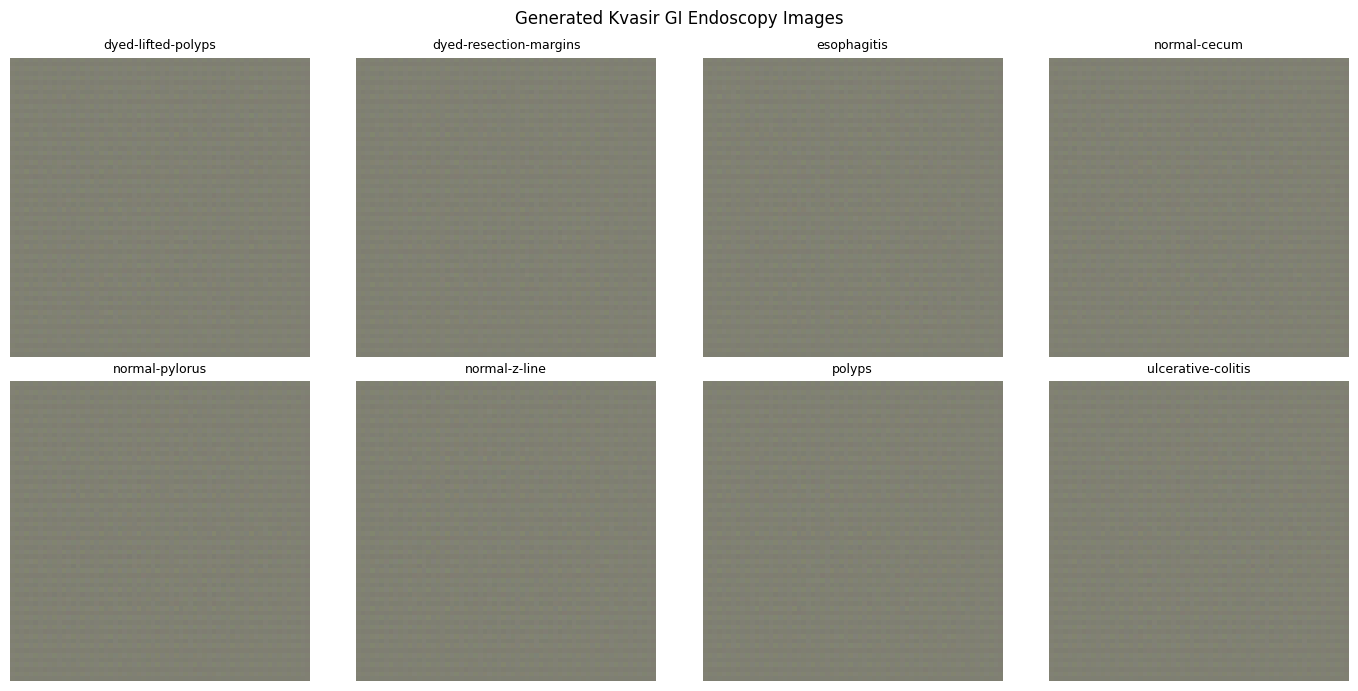

Generated image batch shape: torch.Size([8, 3, 64, 64])
Number of generated images: 8


In [ ]:
import torch
import matplotlib.pyplot as plt

class_names = [
    "dyed-lifted-polyps",
    "dyed-resection-margins",
    "esophagitis",
    "normal-cecum",
    "normal-pylorus",
    "normal-z-line",
    "polyps",
    "ulcerative-colitis"
]

generator.eval()

with torch.no_grad():
    sample_labels = torch.arange(0, NUM_CLASSES, device=device)

    noise = torch.randn(NUM_CLASSES, LATENT_DIM, device=device)

    generated_images = generator(noise, sample_labels)

    generated_images = (generated_images + 1) / 2
    generated_images = generated_images.clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flatten()):
    image = generated_images[i].cpu().permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(class_names[i], fontsize=9)
    ax.axis("off")

plt.suptitle("Generated Kvasir GI Endoscopy Images")
plt.tight_layout()
plt.show()

print("Generated image batch shape:", generated_images.shape)
print("Number of generated images:", len(generated_images))

In [ ]:
train_gan(num_epochs=10)

Epoch [1/10] | D Loss: 0.3185 | G Loss: 4.0547
Epoch [2/10] | D Loss: 0.6452 | G Loss: 2.9817
Epoch [3/10] | D Loss: 0.7895 | G Loss: 2.2855
Epoch [4/10] | D Loss: 0.8797 | G Loss: 2.2291
Epoch [5/10] | D Loss: 0.8474 | G Loss: 2.1501
Epoch [6/10] | D Loss: 0.8243 | G Loss: 2.1068
Epoch [7/10] | D Loss: 0.7849 | G Loss: 2.0758
Epoch [8/10] | D Loss: 0.7720 | G Loss: 2.2787
Epoch [9/10] | D Loss: 0.8619 | G Loss: 2.2571
Epoch [10/10] | D Loss: 0.8041 | G Loss: 2.1703
Training completed!


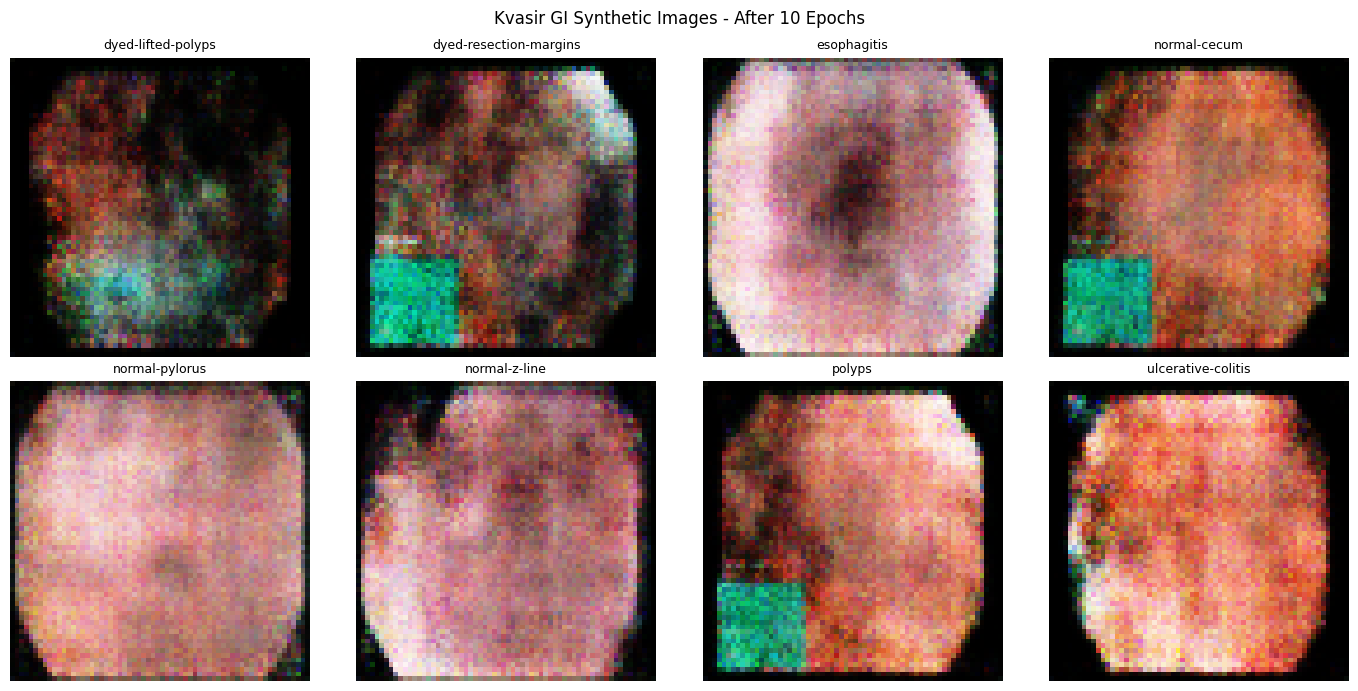

Generated images: torch.Size([8, 3, 64, 64])


In [ ]:
generator.eval()

with torch.no_grad():

    sample_labels = torch.arange(
        0, NUM_CLASSES, device=device
    )

    noise = torch.randn(
        NUM_CLASSES, LATENT_DIM, device=device
    )

    generated_images = generator(noise, sample_labels)

    generated_images = (generated_images + 1) / 2
    generated_images = generated_images.clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flatten()):

    image = generated_images[i].cpu().permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(dataset.classes[i], fontsize=9)
    ax.axis("off")

plt.suptitle("Kvasir GI Synthetic Images - After 10 Epochs")
plt.tight_layout()
plt.show()

print("Generated images:", generated_images.shape)

In [ ]:
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image, make_grid

from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import os
import random
import numpy as npll

In [ ]:
IMG_SIZE = 64
BATCH_SIZE = 64
LATENT_DIM = 100
NUM_CLASSES = 8

EPOCHS = 50

LEARNING_RATE = 0.0002
BETA1 = 0.5

print("GAN settings initialized!")

GAN settings initialized!


In [ ]:
import os

# Expected Kvasir-v2 class folders
expected_classes = {
    "dyed-lifted-polyps",
    "dyed-resection-margins",
    "esophagitis",
    "normal-cecum",
    "normal-pylorus",
    "normal-z-line",
    "polyps",
    "ulcerative-colitis"
}

EXTRACT_PATH = "/content/kvasir_extracted"

# Search for the folder that contains the class folders
DATASET_PATH = None

for root, dirs, files in os.walk(EXTRACT_PATH):
    if expected_classes.issubset(set(dirs)):
        DATASET_PATH = root
        break

if DATASET_PATH is None:
    print("❌ Class folders not found.")
    print("Check extraction folder contents:")
    for root, dirs, files in os.walk(EXTRACT_PATH):
        print(root, "->", dirs[:10], "| files:", len(files))
else:
    print("✅ Dataset folder found:", DATASET_PATH)

    image_paths = []
    labels = []
    classes = sorted(expected_classes)

    for class_name in classes:
        class_path = os.path.join(DATASET_PATH, class_name)

        for file_name in os.listdir(class_path):
            if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
                image_paths.append(os.path.join(class_path, file_name))
                labels.append(class_name)

    print("Total images found:", len(image_paths))
    print("Class folders:", classes)

✅ Dataset folder found: /content/kvasir_extracted/kvasir-dataset
Total images found: 4000
Class folders: ['dyed-lifted-polyps', 'dyed-resection-margins', 'esophagitis', 'normal-cecum', 'normal-pylorus', 'normal-z-line', 'polyps', 'ulcerative-colitis']


In [ ]:
from sklearn.model_selection import train_test_split
from collections import Counter

# 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Temporary data split equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 3200
Validation images: 400
Testing images: 400


In [ ]:
print("Training images per class:")

for class_name, count in sorted(Counter(y_train).items()):
    print(class_name, ":", count)

Training images per class:
dyed-lifted-polyps : 400
dyed-resection-margins : 400
esophagitis : 400
normal-cecum : 400
normal-pylorus : 400
normal-z-line : 400
polyps : 400
ulcerative-colitis : 400


In [ ]:

print("Total:", len(X_train) + len(X_val) + len(X_test))
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Total: 4000
Train: 3200
Validation: 400
Test: 400


In [ ]:
IMG_SIZE = 64
BATCH_SIZE = 64
LATENT_DIM = 100
NUM_CLASSES = 8
EPOCHS = 50
LEARNING_RATE = 0.0002
BETA1 = 0.5

In [ ]:
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_gan = label_encoder.fit_transform(y_train)

print("Class names:", label_encoder.classes_)
print("Encoded labels:", y_train_gan[:10])
print("Number of classes:", len(label_encoder.classes_))

Class names: ['dyed-lifted-polyps' 'dyed-resection-margins' 'esophagitis'
 'normal-cecum' 'normal-pylorus' 'normal-z-line' 'polyps'
 'ulcerative-colitis']
Encoded labels: [3 1 7 0 2 5 4 1 5 5]
Number of classes: 8


In [ ]:
def preprocess_image(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((IMG_SIZE, IMG_SIZE))

    img = np.array(img).astype(np.float32)

    # Normalize pixel values from 0–255 to -1 to +1
    img = (img / 127.5) - 1.0

    # Convert HWC to CHW format for PyTorch
    img = np.transpose(img, (2, 0, 1))

    return torch.tensor(img, dtype=torch.float32)

In [ ]:
class KvasirGANDataset(Dataset):
    def __init__(self, image_paths, labels, label_encoder):
        self.image_paths = image_paths
        self.labels = label_encoder.transform(labels)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = preprocess_image(self.image_paths[idx])
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        return image, label

In [ ]:
train_dataset = KvasirGANDataset(
    X_train,
    y_train,
    label_encoder
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

print("Dataset size:", len(train_dataset))
print("Number of batches:", len(train_loader))

Dataset size: 3200
Number of batches: 50


In [ ]:
real_images, real_labels = next(iter(train_loader))

print("Image batch shape:", real_images.shape)
print("Label batch shape:", real_labels.shape)
print("Image pixel range:",
      real_images.min().item(),
      "to",
      real_images.max().item())

Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])
Image pixel range: -1.0 to 1.0


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=8):
        super(Generator, self).__init__()

        self.label_embedding = nn.Embedding(num_classes, latent_dim)

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256 * 4 * 4),
            nn.BatchNorm1d(256 * 4 * 4),
            nn.ReLU(True),

            nn.Unflatten(1, (256, 4, 4)),

            # 4x4 -> 8x8
            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 8x8 -> 16x16
            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 16x16 -> 32x32
            nn.ConvTranspose2d(64, 32, 4, 2, 1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),

            # 32x32 -> 64x64
            nn.ConvTranspose2d(32, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_vector = self.label_embedding(labels)
        x = noise * label_vector
        return self.model(x)

In [ ]:
class Discriminator(nn.Module):
    def __init__(self, num_classes=8):
        super(Discriminator, self).__init__()

        self.label_embedding = nn.Embedding(num_classes, 64 * 64)

        self.model = nn.Sequential(
            nn.Conv2d(4, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 0)
        )

    def forward(self, image, labels):
        label_map = self.label_embedding(labels)
        label_map = label_map.view(-1, 1, 64, 64)

        x = torch.cat([image, label_map], dim=1)
        output = self.model(x)

        return output.view(-1)

In [ ]:
generator = Generator(
    latent_dim=LATENT_DIM,
    num_classes=NUM_CLASSES
).to(device)

discriminator = Discriminator(
    num_classes=NUM_CLASSES
).to(device)

print("Generator and Discriminator created!")

Generator and Discriminator created!


In [ ]:
noise = torch.randn(4, LATENT_DIM, device=device)
sample_labels = torch.tensor([0, 1, 2, 3], device=device)

with torch.no_grad():
    fake_images = generator(noise, sample_labels)
    predictions = discriminator(fake_images, sample_labels)

print("Generated image shape:", fake_images.shape)
print("Discriminator output shape:", predictions.shape)

Generated image shape: torch.Size([4, 3, 64, 64])
Discriminator output shape: torch.Size([4])


In [ ]:

criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(BETA1, 0.999)
)

print("Loss function and optimizers ready!")

Loss function and optimizers ready!


In [ ]:
EPOCHS = 2

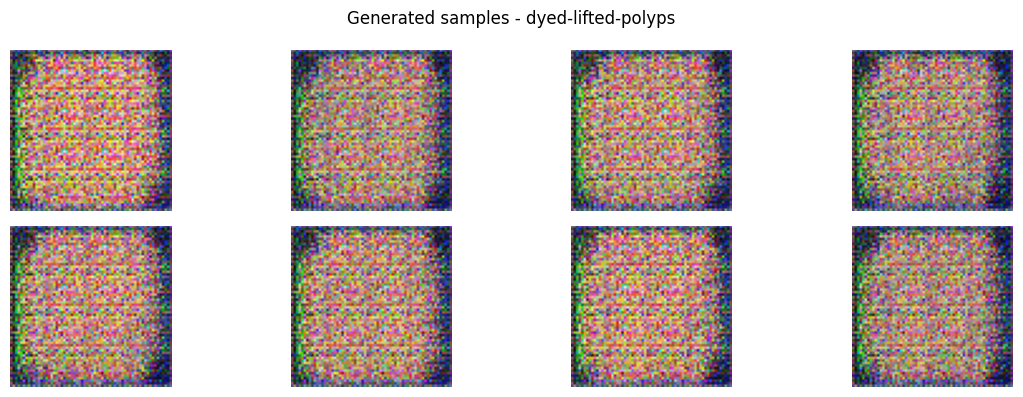

In [ ]:
import matplotlib.pyplot as plt

generator.eval()

sample_class = 0  # Change 0–7 to select a class
num_samples = 8

noise = torch.randn(num_samples, LATENT_DIM, device=device)
labels_sample = torch.full(
    (num_samples,),
    sample_class,
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    generated = generator(noise, labels_sample)

# Convert from [-1, 1] to [0, 1]
generated = (generated + 1) / 2
generated = generated.cpu().permute(0, 2, 3, 1).numpy()

plt.figure(figsize=(12, 4))

for i in range(num_samples):
    plt.subplot(2, 4, i + 1)
    plt.imshow(generated[i].clip(0, 1))
    plt.axis("off")

plt.suptitle(f"Generated samples - {label_encoder.classes_[sample_class]}")
plt.tight_layout()
plt.show()

In [ ]:
import os
import torch

SAVE_PATH = "/content/drive/MyDrive/Kvasir_GAN"

os.makedirs(SAVE_PATH, exist_ok=True)

torch.save({
    "generator": generator.state_dict(),
    "discriminator": discriminator.state_dict(),
    "optimizer_G": optimizer_G.state_dict(),
    "optimizer_D": optimizer_D.state_dict(),
    "epochs_completed": 10
}, os.path.join(SAVE_PATH, "cgan_checkpoint.pth"))

print("GAN model saved successfully!")
print("Saved location:", SAVE_PATH)

GAN model saved successfully!
Saved location: /content/drive/MyDrive/Kvasir_GAN


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader
import numpy as np

# Reproducible dataset splitting
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

indices = np.arange(len(dataset))
labels_all = np.array(dataset.targets)

# 80% training, 20% temporary
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels_all
)

# Split remaining 20% equally into validation and testing
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=labels_all[temp_indices]
)

# Create separate datasets
cnn_train_dataset = Subset(dataset, train_indices)
cnn_val_dataset = Subset(dataset, val_indices)
cnn_test_dataset = Subset(dataset, test_indices)

# Create DataLoaders
cnn_train_loader = DataLoader(
    cnn_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

cnn_val_loader = DataLoader(
    cnn_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

cnn_test_loader = DataLoader(
    cnn_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("CNN Dataset Split Completed!")
print("Training images:", len(cnn_train_dataset))
print("Validation images:", len(cnn_val_dataset))
print("Testing images:", len(cnn_test_dataset))
print("Total images:",
      len(cnn_train_dataset) +
      len(cnn_val_dataset) +
      len(cnn_test_dataset))


CNN Dataset Split Completed!
Training images: 3200
Validation images: 400
Testing images: 400
Total images: 4000


In [ ]:
class KvasirCNN(nn.Module):

    def __init__(self, num_classes=8):
        super(KvasirCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = KvasirCNN(num_classes=NUM_CLASSES).to(device)

print(cnn_model)
print("\nCNN model created successfully!")

KvasirCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [ ]:
# CNN loss function
cnn_criterion = nn.CrossEntropyLoss()

# CNN optimizer
cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    cnn_optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("CNN Loss Function:", cnn_criterion)
print("CNN Optimizer:", cnn_optimizer)
print("Learning Rate:", cnn_optimizer.param_groups[0]["lr"])
print("CNN training setup completed!")

CNN Loss Function: CrossEntropyLoss()
CNN Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning Rate: 0.001
CNN training setup completed!


In [ ]:
import copy

EPOCHS_CNN = 20

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(cnn_model.state_dict())


def train_cnn(num_epochs):

    global best_val_accuracy, best_model_weights

    for epoch in range(num_epochs):

        # -------- TRAINING --------
        cnn_model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in cnn_train_loader:

            images = images.to(device)
            labels = labels.to(device)

            cnn_optimizer.zero_grad()

            outputs = cnn_model(images)
            loss = cnn_criterion(outputs, labels)

            loss.backward()
            cnn_optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        # -------- VALIDATION --------
        cnn_model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in cnn_val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = cnn_model(images)

                loss = cnn_criterion(outputs, labels)

                val_running_loss += loss.item() * images.size(0)

                predictions = torch.argmax(outputs, dim=1)

                val_total += labels.size(0)
                val_correct += (predictions == labels).sum().item()

        val_loss = val_running_loss / val_total
        val_accuracy = 100 * val_correct / val_total

        # Store metrics
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        # Adjust learning rate
        scheduler.step(val_loss)

        # Save best model
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_model_weights = copy.deepcopy(
                cnn_model.state_dict()
            )

            torch.save(
                best_model_weights,
                "/content/drive/MyDrive/Kvasir_GAN/best_cnn_model.pth"
            )

        print(
            f"Epoch [{epoch+1}/{num_epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.2f}%"
        )

    cnn_model.load_state_dict(best_model_weights)

    print("\nCNN Training Completed!")
    print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")

In [ ]:
from PIL import Image, ImageFile
import os

ImageFile.LOAD_TRUNCATED_IMAGES = False

bad_images = []

for class_name in dataset.classes:
    class_path = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(class_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(class_path, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

                with Image.open(image_path) as img:
                    img.convert("RGB").load()

            except Exception as e:
                bad_images.append(image_path)

print("Corrupted images found:", len(bad_images))

for path in bad_images[:20]:
    print(path)

Corrupted images found: 1
/content/kvasir_extracted/kvasir-dataset/esophagitis/cfc39f0a-8aad-4d91-9cf6-899abc19fb43.jpg


In [ ]:
import os
import shutil

bad_image = "/content/kvasir_extracted/kvasir-dataset/esophagitis/cfc39f0a-8aad-4d91-9cf6-899abc19fb43.jpg"

quarantine_folder = "/content/kvasir_corrupted_quarantine"
os.makedirs(quarantine_folder, exist_ok=True)

shutil.move(
    bad_image,
    os.path.join(quarantine_folder, os.path.basename(bad_image))
)

print("Corrupted image moved successfully!")
print("Quarantine folder:", quarantine_folder)


Corrupted image moved successfully!
Quarantine folder: /content/kvasir_corrupted_quarantine


In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
import numpy as np

# Recreate dataset after removing the corrupted image
dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

print("Total valid images:", len(dataset))
print("Classes:", dataset.classes)

# Stratified train, validation and test split
indices = np.arange(len(dataset))
labels_all = np.array(dataset.targets)

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels_all
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=labels_all[temp_indices]
)

cnn_train_dataset = Subset(dataset, train_indices)
cnn_val_dataset = Subset(dataset, val_indices)
cnn_test_dataset = Subset(dataset, test_indices)

# Recreate DataLoaders
cnn_train_loader = DataLoader(
    cnn_train_dataset, batch_size=64,
    shuffle=True, num_workers=0
)

cnn_val_loader = DataLoader(
    cnn_val_dataset, batch_size=64,
    shuffle=False, num_workers=0
)

cnn_test_loader = DataLoader(
    cnn_test_dataset, batch_size=64,
    shuffle=False, num_workers=0
)

print("\nTrain images:", len(cnn_train_dataset))
print("Validation images:", len(cnn_val_dataset))
print("Test images:", len(cnn_test_dataset))

Total valid images: 3999
Classes: ['dyed-lifted-polyps', 'dyed-resection-margins', 'esophagitis', 'normal-cecum', 'normal-pylorus', 'normal-z-line', 'polyps', 'ulcerative-colitis']

Train images: 3199
Validation images: 400
Test images: 400


In [ ]:
train_cnn(EPOCHS_CNN)

Epoch [1/20] | Train Loss: 0.7505 | Train Accuracy: 64.61% | Val Loss: 0.6671 | Val Accuracy: 70.25%
Epoch [2/20] | Train Loss: 0.7126 | Train Accuracy: 66.49% | Val Loss: 0.6405 | Val Accuracy: 67.25%
Epoch [3/20] | Train Loss: 0.6698 | Train Accuracy: 68.30% | Val Loss: 0.7118 | Val Accuracy: 67.50%
Epoch [4/20] | Train Loss: 0.6206 | Train Accuracy: 71.87% | Val Loss: 0.6471 | Val Accuracy: 69.00%
Epoch [5/20] | Train Loss: 0.6184 | Train Accuracy: 72.87% | Val Loss: 0.6128 | Val Accuracy: 72.50%
Epoch [6/20] | Train Loss: 0.6136 | Train Accuracy: 71.27% | Val Loss: 0.6045 | Val Accuracy: 73.00%
Epoch [7/20] | Train Loss: 0.5685 | Train Accuracy: 74.05% | Val Loss: 0.6208 | Val Accuracy: 69.00%
Epoch [8/20] | Train Loss: 0.5379 | Train Accuracy: 75.99% | Val Loss: 0.5641 | Val Accuracy: 73.00%
Epoch [9/20] | Train Loss: 0.5104 | Train Accuracy: 76.46% | Val Loss: 0.5411 | Val Accuracy: 74.00%
Epoch [10/20] | Train Loss: 0.4987 | Train Accuracy: 76.49% | Val Loss: 0.5771 | Val Accura

In [ ]:
import torch
import torch.nn as nn

class KvasirCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cnn_model = KvasirCNN(num_classes=8).to(device)

model_path = "/content/drive/MyDrive/Kvasir_GAN/best_cnn_model.pth"

cnn_model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)

cnn_model.eval()

print("CNN model loaded successfully!")
print("Device:", device)

CNN model loaded successfully!
Device: cuda


In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

zip_path = "/content/drive/MyDrive/kvasir_dataset.zip.zip"

print("ZIP file exists:", os.path.exists(zip_path))
print("ZIP file size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB"
      if os.path.exists(zip_path) else "File not found")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP file exists: True
ZIP file size: 1.15 GB


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/kvasir_dataset.zip.zip"
extract_path = "/content/kvasir_extracted"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

DATASET_PATH = "/content/kvasir_extracted/kvasir-dataset"

print("Dataset extraction completed!")
print("Dataset path exists:", os.path.exists(DATASET_PATH))

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)
    if os.path.isdir(class_path):
        print(class_name, ":", len(os.listdir(class_path)), "files")

Dataset extraction completed!
Dataset path exists: True
dyed-lifted-polyps : 500 files
dyed-resection-margins : 500 files
esophagitis : 500 files
normal-cecum : 500 files
normal-pylorus : 500 files
normal-z-line : 500 files
polyps : 500 files
ulcerative-colitis : 500 files


In [ ]:
from PIL import Image
import os
import shutil

bad_images = []

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in os.listdir(class_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(class_path, filename)

            try:
                with Image.open(image_path) as img:
                    img.verify()

                with Image.open(image_path) as img:
                    img.convert("RGB").load()

            except Exception:
                bad_images.append(image_path)

quarantine_folder = "/content/kvasir_corrupted_quarantine"
os.makedirs(quarantine_folder, exist_ok=True)

for image_path in bad_images:
    shutil.move(
        image_path,
        os.path.join(quarantine_folder, os.path.basename(image_path))
    )

print("Corrupted images found:", len(bad_images))
print("Images moved to quarantine:", len(bad_images))
print("Clean dataset images:", sum(
    len(files) for _, _, files in os.walk(DATASET_PATH)
))

Corrupted images found: 0
Images moved to quarantine: 0
Clean dataset images: 4000


In [ ]:
import os

bad_image = os.path.join(
    DATASET_PATH,
    "esophagitis",
    "cfc39f0a-8aad-4d91-9cf6-899abc19fb43.jpg"
)

print("Previously corrupted image exists:", os.path.exists(bad_image))

Previously corrupted image exists: True


In [ ]:
import os
import shutil

bad_image = os.path.join(
    DATASET_PATH,
    "esophagitis",
    "cfc39f0a-8aad-4d91-9cf6-899abc19fb43.jpg"
)

quarantine_folder = "/content/kvasir_corrupted_quarantine"
os.makedirs(quarantine_folder, exist_ok=True)

if os.path.exists(bad_image):
    shutil.move(
        bad_image,
        os.path.join(quarantine_folder, os.path.basename(bad_image))
    )

print("Corrupted image successfully excluded!")
print("Remaining dataset images:",
      sum(len(files) for _, _, files in os.walk(DATASET_PATH)))

Corrupted image successfully excluded!
Remaining dataset images: 3999


In [ ]:
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

indices = np.arange(len(dataset))
labels_all = np.array(dataset.targets)

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels_all
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=labels_all[temp_indices]
)

cnn_test_dataset = Subset(dataset, test_indices)

cnn_test_loader = DataLoader(
    cnn_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

print("Dataset:", len(dataset))
print("Test images:", len(cnn_test_dataset))
print("Test DataLoader ready!")

Dataset: 3999
Test images: 400
Test DataLoader ready!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
import torch

cnn_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in cnn_test_loader:
        images = images.to(device)

        outputs = cnn_model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)

print("FINAL TEST ACCURACY:", round(test_accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT:\n")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes,
    digits=4
))

FINAL TEST ACCURACY: 84.0 %

CLASSIFICATION REPORT:

                        precision    recall  f1-score   support

    dyed-lifted-polyps     0.8049    0.6600    0.7253        50
dyed-resection-margins     0.7069    0.8200    0.7593        50
           esophagitis     0.8776    0.8600    0.8687        50
          normal-cecum     0.9000    0.9000    0.9000        50
        normal-pylorus     0.8929    1.0000    0.9434        50
         normal-z-line     0.8750    0.8400    0.8571        50
                polyps     0.8222    0.7400    0.7789        50
    ulcerative-colitis     0.8491    0.9000    0.8738        50

              accuracy                         0.8400       400
             macro avg     0.8411    0.8400    0.8383       400
          weighted avg     0.8411    0.8400    0.8383       400



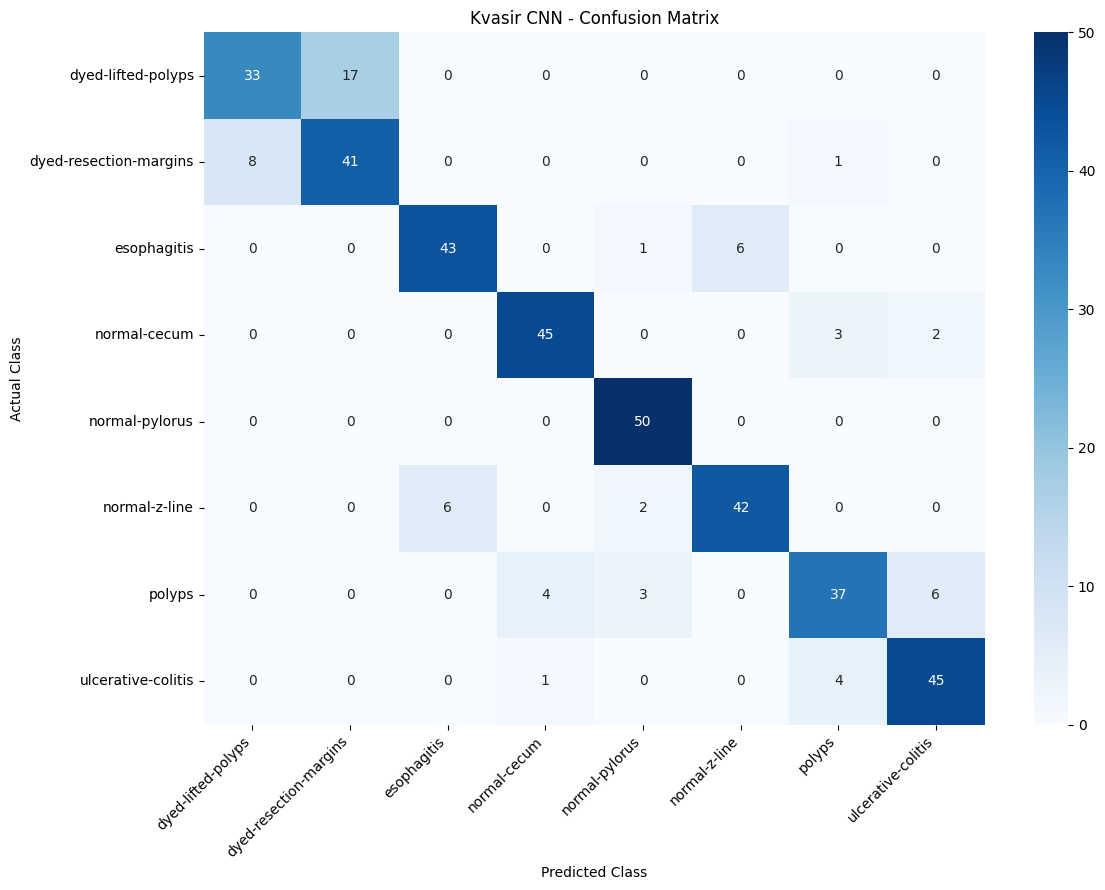

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Kvasir CNN - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


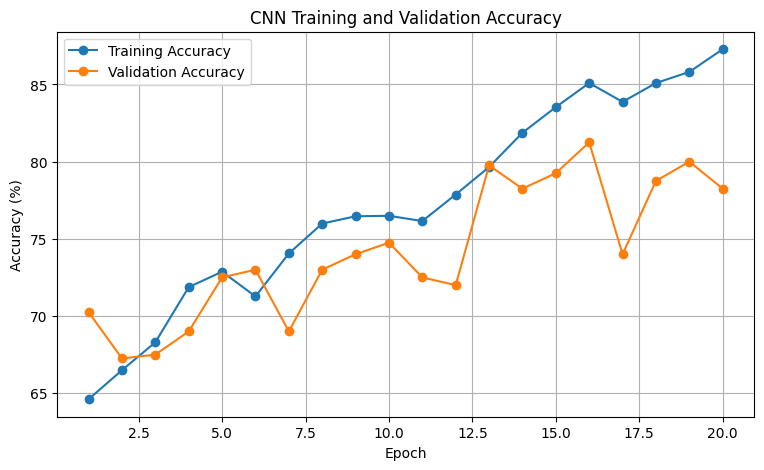

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, 21)

train_accuracy = [
    64.61, 66.49, 68.30, 71.87, 72.87,
    71.27, 74.05, 75.99, 76.46, 76.49,
    76.15, 77.87, 79.65, 81.87, 83.53,
    85.09, 83.87, 85.09, 85.81, 87.28
]

val_accuracy = [
    70.25, 67.25, 67.50, 69.00, 72.50,
    73.00, 69.00, 73.00, 74.00, 74.75,
    72.50, 72.00, 79.75, 78.25, 79.25,
    81.25, 74.00, 78.75, 80.00, 78.25
]

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_accuracy, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accuracy, marker='o', label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

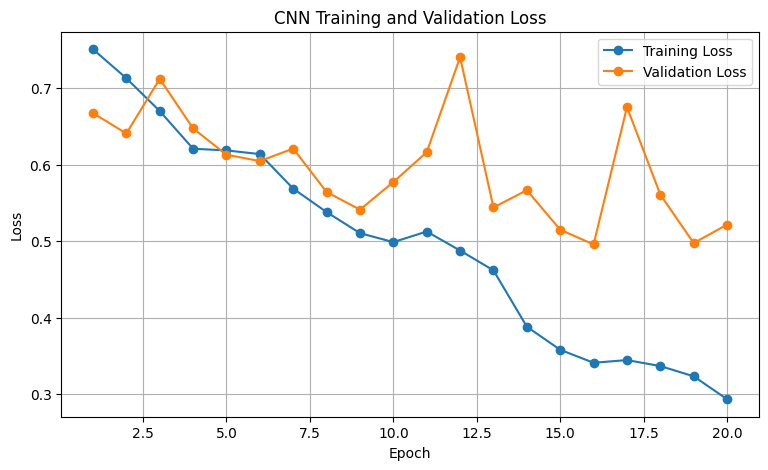

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, 21)

train_loss = [
    0.7505, 0.7126, 0.6698, 0.6206, 0.6184,
    0.6136, 0.5685, 0.5379, 0.5104, 0.4987,
    0.5125, 0.4877, 0.4618, 0.3883, 0.3581,
    0.3412, 0.3447, 0.3369, 0.3235, 0.2936
]

val_loss = [
    0.6671, 0.6405, 0.7118, 0.6471, 0.6128,
    0.6045, 0.6208, 0.5641, 0.5411, 0.5771,
    0.6161, 0.7401, 0.5439, 0.5665, 0.5148,
    0.4957, 0.6749, 0.5607, 0.4974, 0.5216
]

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, marker='o', label='Training Loss')
plt.plot(epochs, val_loss, marker='o', label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
from PIL import Image
import torch
import matplotlib.pyplot as plt

class_names = dataset.classes

def predict_endoscopy_image(image_path):

    image = Image.open(image_path).convert("RGB")

    input_image = transform(image).unsqueeze(0).to(device)

    cnn_model.eval()

    with torch.no_grad():
        output = cnn_model(input_image)
        probabilities = torch.softmax(output, dim=1)

        confidence, predicted_class = torch.max(probabilities, dim=1)

    predicted_label = class_names[predicted_class.item()]
    confidence_score = confidence.item() * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_label}\n"
        f"Confidence: {confidence_score:.2f}%"
    )
    plt.show()

    print("Predicted Class:", predicted_label)
    print("Confidence:", f"{confidence_score:.2f}%")

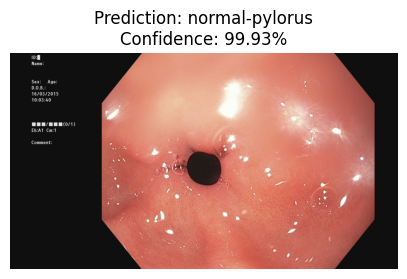

Predicted Class: normal-pylorus
Confidence: 99.93%


In [ ]:
import os

test_image_path = os.path.join(
    DATASET_PATH,
    "normal-pylorus",
    os.listdir(os.path.join(DATASET_PATH, "normal-pylorus"))[0]
)

predict_endoscopy_image(test_image_path)


In [ ]:
import os
import torch

save_path = "/content/drive/MyDrive/Kvasir_GAN"

os.makedirs(save_path, exist_ok=True)

torch.save(
    cnn_model.state_dict(),
    os.path.join(save_path, "final_kvasir_cnn.pth")
)

print("Final CNN model saved successfully!")
print("Location:", save_path)

Final CNN model saved successfully!
Location: /content/drive/MyDrive/Kvasir_GAN


Upload an Endoscopy Image (JPG, JPEG or PNG)


Saving 0a4ef674-6ccd-4b26-a8e0-a8d7e3f2f6be.jpg to 0a4ef674-6ccd-4b26-a8e0-a8d7e3f2f6be.jpg


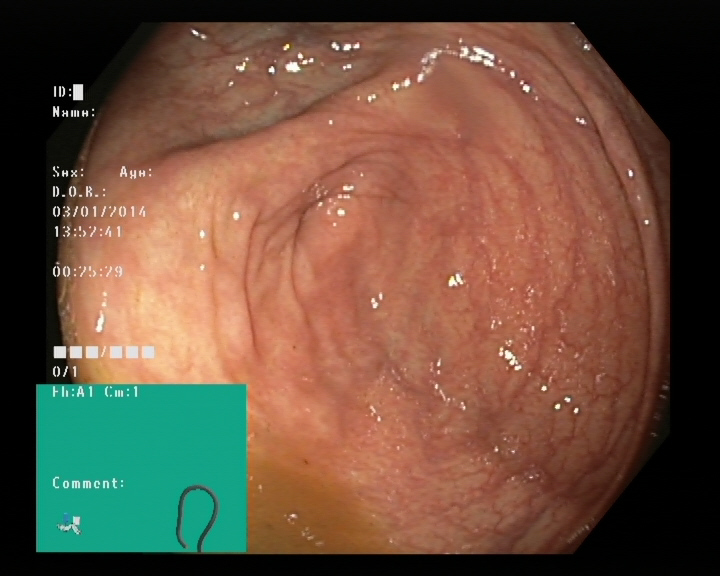

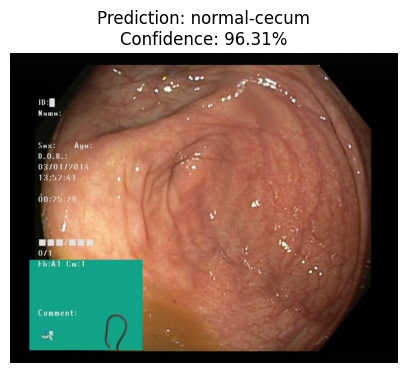

Predicted Class: normal-cecum
Confidence: 96.31%


In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image
import io

print("Upload an Endoscopy Image (JPG, JPEG or PNG)")

uploaded = files.upload()

for filename in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

    display(image)

    # Save uploaded image temporarily
    image_path = "/content/uploaded_endoscopy_image.jpg"
    image.save(image_path)

    # Predict using our trained CNN
    predict_endoscopy_image(image_path)

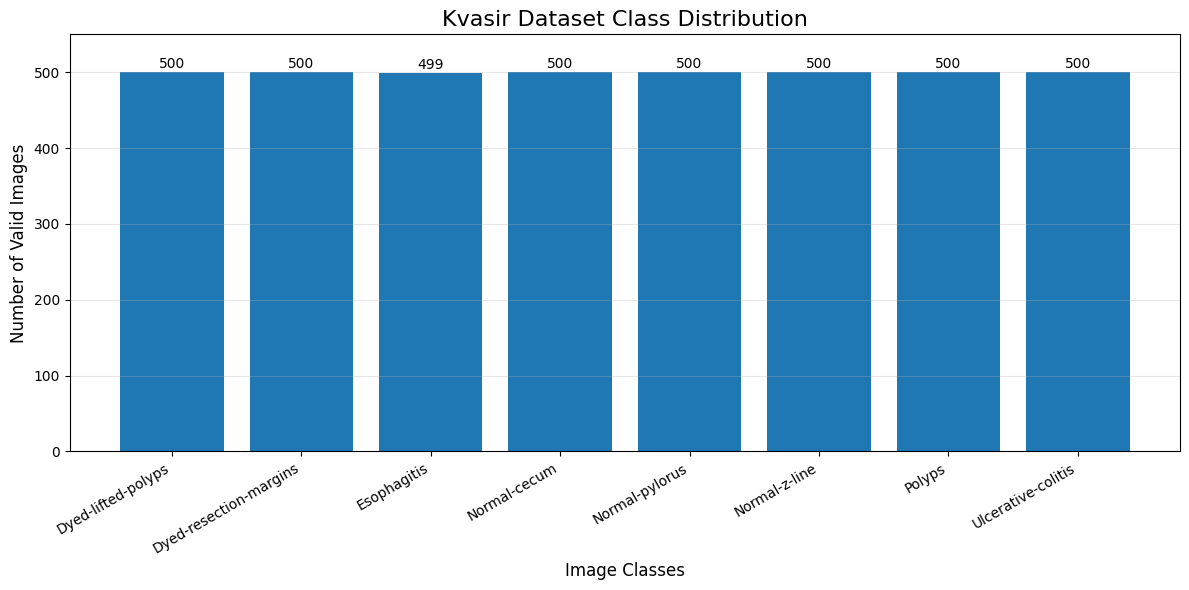

In [ ]:
import matplotlib.pyplot as plt

# Kvasir dataset class names
classes = [
    "Dyed-lifted-polyps",
    "Dyed-resection-margins",
    "Esophagitis",
    "Normal-cecum",
    "Normal-pylorus",
    "Normal-z-line",
    "Polyps",
    "Ulcerative-colitis"
]

# Number of valid images in each class
image_counts = [500, 500, 499, 500, 500, 500, 500, 500]

# Create bar graph
plt.figure(figsize=(12, 6))

bars = plt.bar(classes, image_counts)

# Add title and labels
plt.title("Kvasir Dataset Class Distribution", fontsize=16)
plt.xlabel("Image Classes", fontsize=12)
plt.ylabel("Number of Valid Images", fontsize=12)

# Set Y-axis limit
plt.ylim(0, 550)

# Display image count above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 5,
        str(int(height)),
        ha='center',
        fontsize=10
    )

# Rotate X-axis labels
plt.xticks(rotation=30, ha='right')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

# Save figure in high resolution
plt.savefig(
    "Kvasir_Dataset_Class_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
